# Branch A — provisional segment-weighted COM → GRF

**Goal:** reconstruct a provisional COM from the exported 12 SAM keypoints; calculate Newtonian total GRF **only after** metric global translation, gravity direction and participant mass are verified. The available export does not capture complete HAT geometry, arms, global translation or exact anthropometry. This is a **sensitivity/feasibility baseline**, not validated whole-body dynamics.

Do not change `GLOBAL_METRIC_CONFIRMED` merely to make the code run. Export root translation or establish metrically scaled camera/world coordinates first. Keep the SAM and Vicon datasets independent; Vicon is for external validation.

In [60]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir(): ROOT = ROOT.parent
if not (ROOT / "src").is_dir(): raise FileNotFoundError("Cannot find project root")

SUBJECT = "S11"
TRIAL = "lunge_01"
CAMERA = "cam0"
DATA_DIR = ROOT / "lunge_sam_out" / SUBJECT / TRIAL
TRIAL_RESULTS = ROOT / "results" / SUBJECT / TRIAL
C3D_PATH = (DATA_DIR / f"{SUBJECT.lower()}_lunge.c3d")

# Camera-independent Vicon reference
MEASURED_DIR = TRIAL_RESULTS / "kinetics"

# Camera-specific SAM physics-based estimation
OUT_DIR = (
    TRIAL_RESULTS / "kinetics_validation"
    / CAMERA / "branch_a"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)
NPZ_PATH = DATA_DIR / f"{SUBJECT.lower()}_lunge_{CAMERA}_sam_raw.npz"

# Crucial: set to True ONLY if keypoints have been verified in a stable, metric,
# gravity-aligned global frame. Current bilateral export does NOT establish this.
GLOBAL_METRIC_CONFIRMED = False
BODY_MASS_KG = None  # Replace with participant's measured mass; e.g. 75.0
VERTICAL_AXIS = 2   # Verify with controlled movement / camera->world transform
VERTICAL_SIGN = 1.0 # +1 only if increasing coordinate = upward
SMOOTH_WINDOW_S = 0.55  # Exploratory: low-rate sampling; report sensitivity

if not NPZ_PATH.exists(): raise FileNotFoundError(NPZ_PATH)
raw = np.load(NPZ_PATH, allow_pickle=False)
print("NPZ fields:", raw.files)
t_ms = raw["time_ms"].astype(float)
frame = raw["frame_index"]
names = [str(x) for x in raw["keypoint_names"]]
xyz = raw["keypoints3d"].astype(float)
assert xyz.ndim == 3 and xyz.shape == (len(t_ms),len(names),3)
assert np.all(np.diff(t_ms)>0), "Non-increasing timestamps"
print("Frames:",len(t_ms),"dt median (ms):",np.median(np.diff(t_ms)))
print("Keys:",names)


NPZ fields: ['frame_index', 'time_ms', 'keypoint_names', 'keypoints3d', 'R_rhip_local', 'R_rknee_local', 'R_rankle_local', 'R_lhip_local', 'R_lknee_local', 'R_lankle_local', 'pred_cam_t', 'global_rot', 'pred_keypoints_3d_full', 'pred_joint_coords', 'pred_global_rots_full', 'shape_params', 'scale_params', 'mhr_model_params', 'focal_length', 'bbox']
Frames: 123 dt median (ms): 83.33333333333331
Keys: ['l_sh', 'r_sh', 'l_hip', 'r_hip', 'l_knee', 'r_knee', 'l_ankle', 'r_ankle', 'l_big_toe', 'r_big_toe', 'l_small_toe', 'r_small_toe', 'l_heel', 'r_heel']


## 1. Segment COM estimates

The default **illustrative** lumped fractions are deliberately transparent, not precise de Leva anthropometric data: HAT (head, arms and trunk) 67.8%, each thigh 10.0%, each shank 4.65%, each foot 1.45%. COM location fractions are also placeholders: 43.3% along thigh/shank from proximal joint; foot midpoint ankle-to-toe; HAT halfway between pelvis and shoulder midpoints. The assumed HAT location will often be wrong during arm movements and trunk flexion. **Replace these with a consistent published body-segment parameter model and full required landmarks before thesis-grade inference.**

COM shape: (123, 3)  mass weights sum: 0.9999999999999999


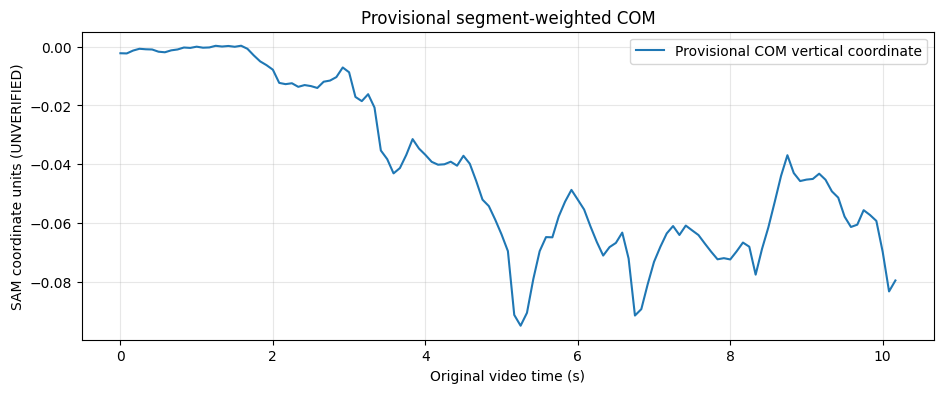

In [61]:
def kp(name):
    if name not in names: raise KeyError(f"Missing {name}; available: {names}")
    return xyz[:,names.index(name),:]

mid_hips = (kp("l_hip") + kp("r_hip")) / 2
mid_shoulders = (kp("l_sh") + kp("r_sh")) / 2
segment_com = {
    "HAT_proxy": mid_hips + 0.5 * (mid_shoulders-mid_hips),
}
fractions = {"HAT_proxy":0.678}
for side in ("l","r"):
    hip,knee,ankle = (kp(f"{side}_{j}") for j in ("hip","knee","ankle"))
    toe = (kp(f"{side}_big_toe")+kp(f"{side}_small_toe"))/2
    segment_com[f"{side}_thigh"] = hip + .433*(knee-hip)
    segment_com[f"{side}_shank"] = knee + .433*(ankle-knee)
    segment_com[f"{side}_foot"] = ankle + .5*(toe-ankle)
    fractions.update({f"{side}_thigh":.100,f"{side}_shank":.0465,f"{side}_foot":.0145})
assert np.isclose(sum(fractions.values()),1.0)
com = sum(fractions[k]*pos for k,pos in segment_com.items())
print("COM shape:",com.shape," mass weights sum:",sum(fractions.values()))

fig,ax=plt.subplots(figsize=(11,4))
ax.plot(t_ms/1000,com[:,VERTICAL_AXIS],label="Provisional COM vertical coordinate")
ax.set(xlabel="Original video time (s)",ylabel="SAM coordinate units (UNVERIFIED)",title="Provisional segment-weighted COM")
ax.grid(alpha=.3);ax.legend();plt.show()


## 2. Gap-aware smoothing and second derivatives

Savitzky–Golay differentiation assumes nearly uniform sample spacing within each uninterrupted segment. It cannot create missing high-frequency information. We split on large gaps, avoid interpolating over them, and return NaNs for segments too short for a stable fit. Test several window sizes before interpreting acceleration.

Savgol window: 7 samples = 0.583s


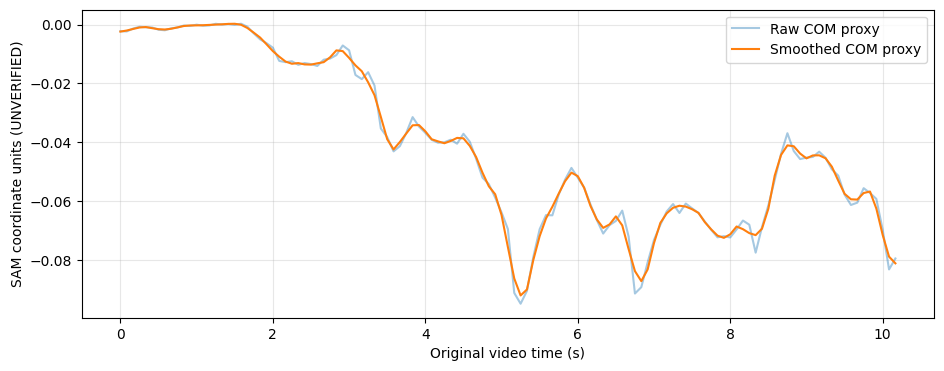

In [62]:
def smooth_and_accel(t_ms, xyz_com, window_s=0.55, polyorder=3, gap_factor=1.8):
    t=np.asarray(t_ms,dtype=float)/1000
    v=np.asarray(xyz_com,dtype=float)
    dt=np.diff(t)
    if not np.all(dt>0):raise ValueError("Times must increase")
    median_dt=float(np.median(dt))
    split=np.r_[0,np.where(dt>gap_factor*median_dt)[0]+1,len(t)]
    sm=np.full_like(v,np.nan)
    acc=np.full_like(v,np.nan)
    win=max(polyorder+2,int(round(window_s/median_dt)))
    if win%2==0:win+=1
    for a,b in zip(split[:-1],split[1:]):
        if b-a < win:continue
        tt=t[a:b]
        d=np.diff(tt)
        if np.max(np.abs(d-np.median(d))) > .02*np.median(d):
            print(f"Skipping non-uniform interval {a}:{b}")
            continue
        if not np.isfinite(v[a:b]).all():
            print(f"Skipping segment with missing coordinates {a}:{b}")
            continue
        for j in range(3):
            sm[a:b,j]=savgol_filter(v[a:b,j],win,polyorder,delta=median_dt,deriv=0)
            acc[a:b,j]=savgol_filter(v[a:b,j],win,polyorder,delta=median_dt,deriv=2)
    return sm,acc,win,median_dt

com_smooth, a_com, window_samples, dt = smooth_and_accel(t_ms,com,SMOOTH_WINDOW_S)
print(f"Savgol window: {window_samples} samples = {window_samples*dt:.3f}s")
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(t_ms/1000,com[:,VERTICAL_AXIS],alpha=.4,label="Raw COM proxy")
ax.plot(t_ms/1000,com_smooth[:,VERTICAL_AXIS],label="Smoothed COM proxy")
ax.set(xlabel="Original video time (s)",ylabel="SAM coordinate units (UNVERIFIED)")
ax.grid(alpha=.3);ax.legend();plt.show()


## 3. Newtonian GRF with mandatory verification gate

`Fz = mass * (vertical_COM_acceleration + 9.80665)` requires **metres**, **seconds**, **upward positive** and a stable **global frame**. A camera-relative pelvis-normalized reconstruction cannot be differentiated into ground reaction force. No force output is written while these conditions remain unverified.

In [63]:
if not GLOBAL_METRIC_CONFIRMED:
    print("STOP: GRF not computed. SAM global metric translation/scale/gravity alignment unverified.")
    print("You CAN inspect the COM proxy; it cannot yet be interpreted as whole-body GRF.")
else:
    if BODY_MASS_KG is None or not (20 <= float(BODY_MASS_KG) <= 300):
        raise ValueError("Enter verified participant BODY_MASS_KG")
    if VERTICAL_SIGN not in (-1.0,1.0):raise ValueError("VERTICAL_SIGN must be ±1")
    fz = float(BODY_MASS_KG)*(VERTICAL_SIGN*a_com[:,VERTICAL_AXIS]+9.80665)
    fig,ax=plt.subplots(figsize=(12,4))
    ax.plot(t_ms/1000,fz,label="SAM-derived total vertical GRF")
    ax.axhline(float(BODY_MASS_KG)*9.80665,ls="--",label="Body weight")
    ax.set(xlabel="Original video time (s)",ylabel="N",title="Exploratory SAM COM-based force")
    ax.legend();ax.grid(alpha=.3);plt.show()
    np.savez_compressed(OUT_DIR/"sam_total_grf_provisional.npz",
                        original_video_time_ms=t_ms,com_m=com,com_smooth_m=com_smooth,
                        com_accel_m_s2=a_com,total_fz_N=fz,
                        body_mass_kg=BODY_MASS_KG,smoothing_window_s=SMOOTH_WINDOW_S)


STOP: GRF not computed. SAM global metric translation/scale/gravity alignment unverified.
You CAN inspect the COM proxy; it cannot yet be interpreted as whole-body GRF.


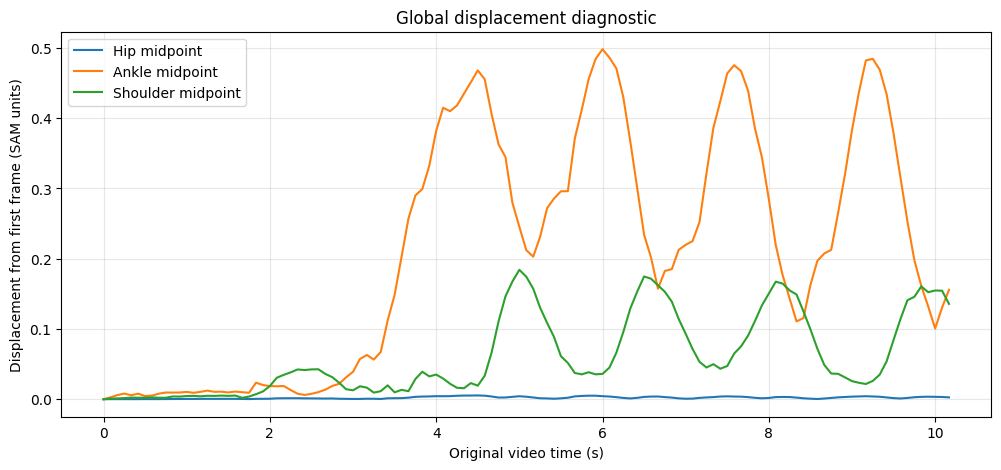

Hip midpoint range: [0.00437752 0.00668117 0.00696893]
Ankle midpoint range: [0.20068116 0.48691821 0.30884597]
Shoulder midpoint range: [0.10674001 0.0804559  0.21110116]


In [64]:
kp = raw["keypoints3d"]
names = list(raw["keypoint_names"])
t = raw["time_ms"] / 1000

def landmark(name):
    return kp[:, names.index(name), :]

hip_mid = 0.5 * (landmark("l_hip") + landmark("r_hip"))
ankle_mid = 0.5 * (landmark("l_ankle") + landmark("r_ankle"))
shoulder_mid = 0.5 * (landmark("l_sh") + landmark("r_sh"))

fig, ax = plt.subplots(figsize=(12, 5))

for label, trajectory in [
    ("Hip midpoint", hip_mid),
    ("Ankle midpoint", ankle_mid),
    ("Shoulder midpoint", shoulder_mid),
]:
    displacement = np.linalg.norm(
        trajectory - trajectory[0],
        axis=1
    )
    ax.plot(t, displacement, label=label)
    
ax.set(
    xlabel="Original video time (s)",
    ylabel="Displacement from first frame (SAM units)",
    title="Global displacement diagnostic",
)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("Hip midpoint range:", np.ptp(hip_mid, axis=0))
print("Ankle midpoint range:", np.ptp(ankle_mid, axis=0))
print("Shoulder midpoint range:", np.ptp(shoulder_mid, axis=0))

pred_cam_t shape: (123, 3)
global_rot shape: (123, 3)


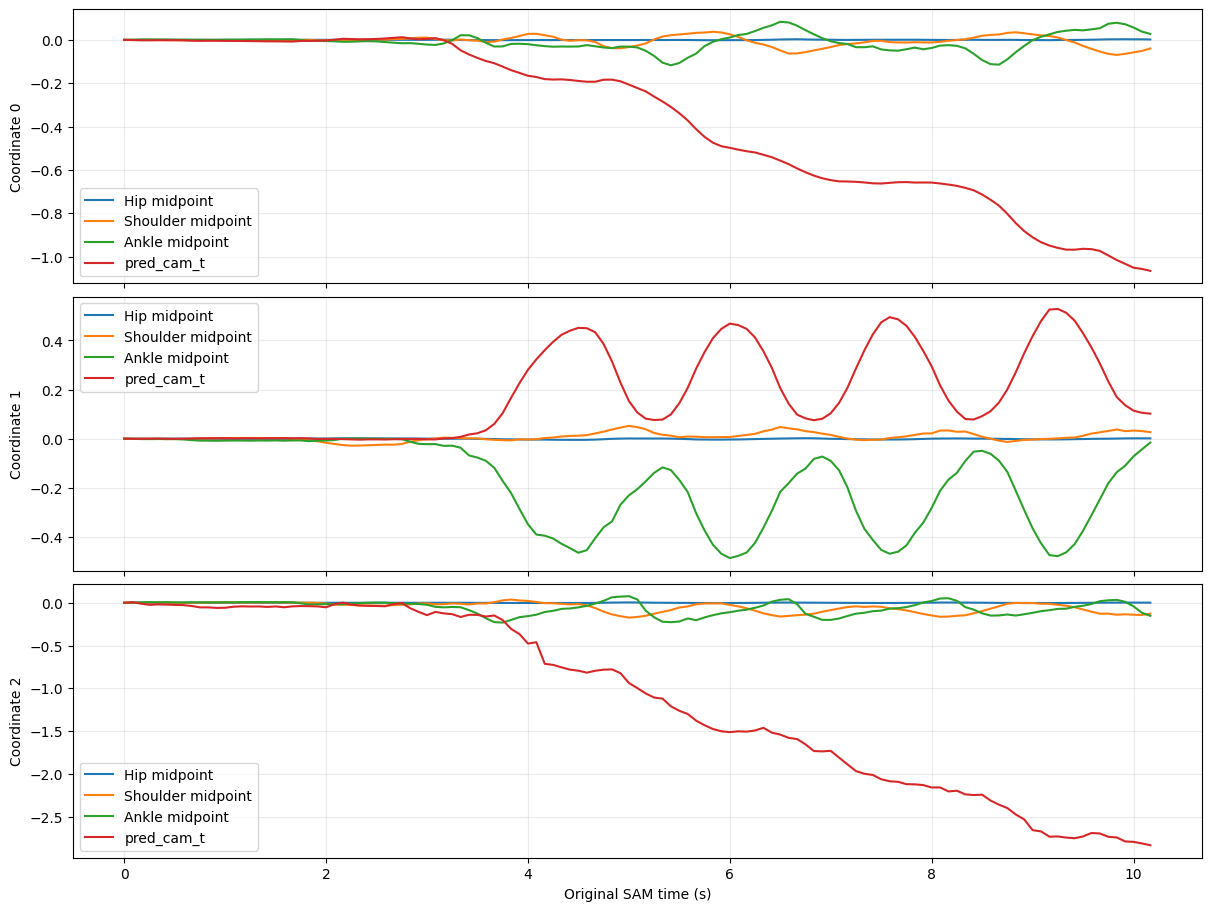


Coordinate ranges:
Hip midpoint         [0.0044 0.0067 0.007 ]
Shoulder midpoint    [0.1067 0.0805 0.2111]
Ankle midpoint       [0.2007 0.4869 0.3088]
pred_cam_t           [1.0784 0.5318 2.8436]


In [65]:

# Inspect pelvis, shoulder and ankle translation
# and compare with SAM's predicted camera translation.

t_s = t_ms / 1000.0

hip_mid = (xyz[:, names.index("l_hip"), :] + xyz[:, names.index("r_hip"), :]) / 2
shoulder_mid = (xyz[:, names.index("l_sh"), :] + xyz[:, names.index("r_sh"), :]) / 2
ankle_mid = (xyz[:, names.index("l_ankle"), :] + xyz[:, names.index("r_ankle"), :]) / 2

pred_cam_t = np.asarray(raw["pred_cam_t"], dtype=float)
global_rot = np.asarray(raw["global_rot"], dtype=float)

print("pred_cam_t shape:", pred_cam_t.shape)
print("global_rot shape:", global_rot.shape)

signals = {
    "Hip midpoint": hip_mid,
    "Shoulder midpoint": shoulder_mid,
    "Ankle midpoint": ankle_mid,
    "pred_cam_t": pred_cam_t,
}

fig, axes = plt.subplots(
    3, 1, figsize=(12, 9),
    sharex=True,
    layout="constrained",
)

for axis, ax in enumerate(axes):
    for name, values in signals.items():
        if values.shape != (len(t_s), 3):
            continue

        displacement = values[:, axis] - values[0, axis]

        ax.plot(
            t_s,
            displacement,
            label=name,
        )

    ax.set_ylabel(f"Coordinate {axis}")
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Original SAM time (s)")
plt.show()

print("\nCoordinate ranges:")

for name, values in signals.items():
    if values.shape == (len(t_s), 3):
        print(
            f"{name:20s}",
            np.round(np.ptp(values, axis=0), 4)
        )



In [66]:

# Inspect full-body reconstruction fields before
# applying any camera/world transformation.

fields = [
    "keypoints3d",
    "pred_cam_t",
    "global_rot",
    "pred_keypoints_3d_full",
    "pred_joint_coords",
    "pred_global_rots_full",
    "scale_params",
    "mhr_model_params",
]

for field in fields:
    if field not in raw.files:
        continue

    arr = raw[field]

    print(f"\n{field}")
    print("  Shape:", arr.shape)
    print("  Dtype:", arr.dtype)

    if np.issubdtype(arr.dtype, np.number):
        finite = arr[np.isfinite(arr)]

        if finite.size:
            print(
                "  Range:",
                np.min(finite),
                "to",
                np.max(finite)
            )

            print(
                "  First values:",
                finite.ravel()[:6]
            )

print("NPZ:", NPZ_PATH)
print("Frames:", len(raw["time_ms"]))
print("Time range (s):", raw["time_ms"][0] / 1000,
      raw["time_ms"][-1] / 1000)
print("Median dt (ms):", np.median(np.diff(raw["time_ms"])))
print("Frame-index steps:",
      np.unique(np.diff(raw["frame_index"]), return_counts=True))



keypoints3d
  Shape: (123, 14, 3)
  Dtype: float64
  Range: -1.4087129831314087 to 0.6339190006256104
  First values: [ 0.16266899 -1.36151636 -0.0753904  -0.17037052 -1.35691619  0.01665857]

pred_cam_t
  Shape: (123, 3)
  Dtype: float64
  Range: -0.46710631251335144 to 5.245029449462891
  First values: [0.59901273 0.903413   5.23759365 0.59791303 0.90281761 5.24502945]

global_rot
  Shape: (123, 3)
  Dtype: float64
  Range: -0.43837904930114746 to 0.25569066405296326
  First values: [ 0.05085436 -0.27135241 -0.01801332  0.05084895 -0.26599324 -0.01345019]

pred_keypoints_3d_full
  Shape: (123, 70, 3)
  Dtype: float64
  Range: -1.6260886192321777 to 0.6339190006256104
  First values: [-0.05255798 -1.60085535 -0.15976369 -0.00645531 -1.62492681 -0.1289729 ]

pred_joint_coords
  Shape: (123, 127, 3)
  Dtype: float64
  Range: -1.697683572769165 to 0.6064771413803101
  First values: [ 0.         -0.         -0.          0.         -0.92398697 -0.        ]

pred_global_rots_full
  Shape: 

- Global translation is explicitly initialized to zero when generating the body model. This supports our interpretation that its 3D joint coordinates are root-relative

- global_rot is represented as Euler angles using a ZYX convention, derived from a predicted 6D rotation. It should not be treated as an arbitrary XYZ rotation vector. The implementation also flips the Y and Z coordinates of the generated keypoints to account for a camera-coordinate convention.Global translation is explicitly initialized to zero when generating the body model. This supports our interpretation that its 3D joint coordinates are root-relative.

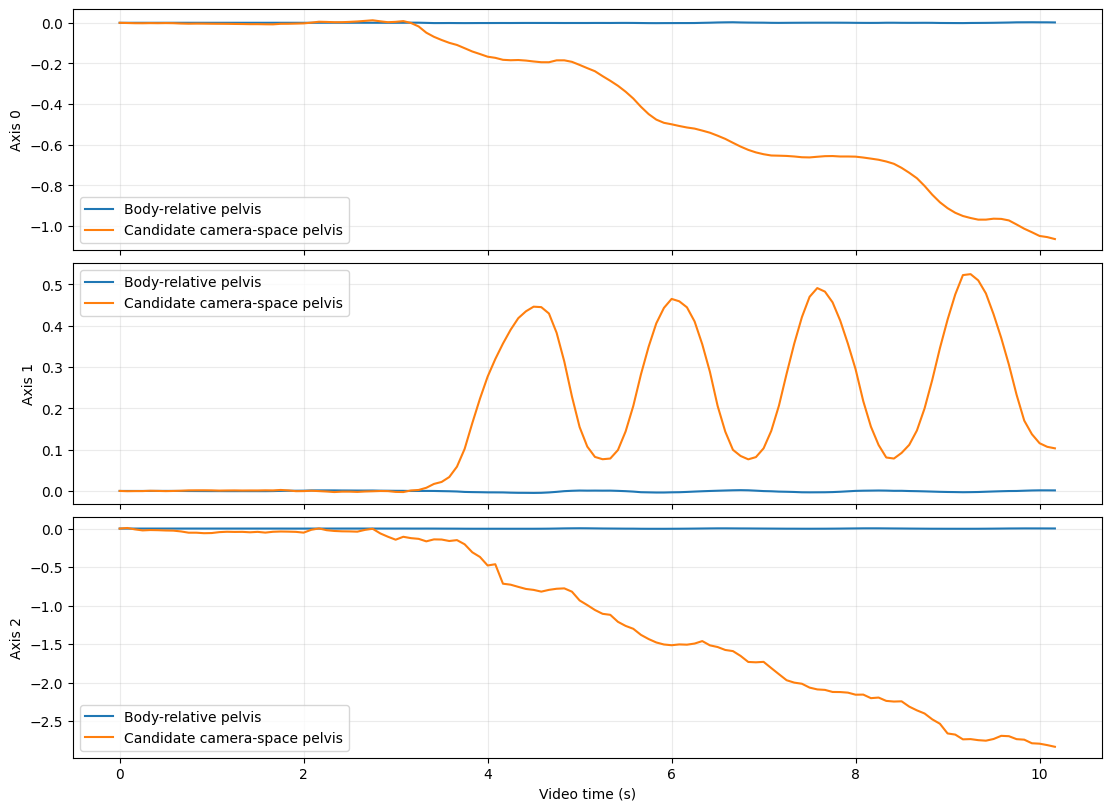

In [67]:
# ------------ Verify pelvis translation in local vs. camera space --------------

with np.load(NPZ_PATH, allow_pickle=False) as data:
    t_ms = np.asarray(data["time_ms"], dtype=float)
    local_kp = np.asarray(data["keypoints3d"], dtype=float)
    names = [str(n) for n in data["keypoint_names"]]
    cam_t = np.asarray(data["pred_cam_t"], dtype=float)

assert local_kp.shape == (len(t_ms), len(names), 3)
assert cam_t.shape == (len(t_ms), 3)

# Candidate only: verify against original exporter and camera geometry.
camera_kp_candidate = local_kp + cam_t[:, None, :]

hip_idx_l = names.index("l_hip")
hip_idx_r = names.index("r_hip")

hip_local = 0.5 * (
    local_kp[:, hip_idx_l] + local_kp[:, hip_idx_r]
)

hip_camera = 0.5 * (
    camera_kp_candidate[:, hip_idx_l]
    + camera_kp_candidate[:, hip_idx_r]
)

fig, axes = plt.subplots(
    3, 1, figsize=(11, 8),
    sharex=True, layout="constrained"
)

for axis in range(3):
    axes[axis].plot(
        t_ms / 1000,
        hip_local[:, axis] - hip_local[0, axis],
        label="Body-relative pelvis"
    )
    axes[axis].plot(
        t_ms / 1000,
        hip_camera[:, axis] - hip_camera[0, axis],
        label="Candidate camera-space pelvis"
    )
    axes[axis].set_ylabel(f"Axis {axis}")
    axes[axis].grid(alpha=0.25)
    axes[axis].legend()

axes[-1].set_xlabel("Video time (s)")
plt.show()

In [68]:
t_s = t_ms / 1000.0

rows = []

for axis in range(3):
    trajectory = hip_camera[:, axis]

    rows.append({
        "axis": axis,
        "start": trajectory[0],
        "end": trajectory[-1],
        "net_displacement": trajectory[-1] - trajectory[0],
        "coordinate_range": np.ptp(trajectory),
    })

displacement_qc = pd.DataFrame(rows)
display(displacement_qc.round(3))

,axis,start,end,net_displacement,coordinate_range
0,0,0.598,-0.467,-1.064,1.077
1,1,-0.002,0.101,0.103,0.528
2,2,5.233,2.399,-2.835,2.842


In [69]:
import ezc3d

c3d = ezc3d.c3d(str(C3D_PATH))

labels = [
    label.strip()
    for label in c3d["parameters"]["POINT"]["LABELS"]["value"]
]

points = np.asarray(c3d["data"]["points"], dtype=float)

point_rate = float(c3d["header"]["points"]["frame_rate"])

vicon_time_s = np.arange(points.shape[2]) / point_rate

def get_vicon_marker(name):
    idx = labels.index(name)
    marker = points[:3, idx, :].T.copy()
    marker[points[3, idx, :] < 0] = np.nan
    return marker

# Midpoint between anterior pelvic markers
lasis = get_vicon_marker("LASI")
rasis = get_vicon_marker("RASI")

vicon_pelvis = (lasis + rasis) / 2

# Convert marker coordinates from mm to metres,
# assuming the C3D POINT units are confirmed as mm.
vicon_pelvis_m = vicon_pelvis / 1000

print(
    "Vicon pelvis coordinate ranges (m):",
    np.nanmax(vicon_pelvis_m, axis=0)
    - np.nanmin(vicon_pelvis_m, axis=0)
)

OSError: The c3d file could not be opened, please verify the path: unspecified iostream_category error

## 4. Compare to force-plate reference (only after camera synchronization)

The `bilateral_grf_reference.npz` uses the **Vicon C3D relative clock**. SAM NPZ timestamps are on the **original video clock**, so neither curves nor metrics should be compared until you have a reviewed camera-specific mapping. Also, total Vicon plate force equals whole-body GRF only during complete instrumented support. In the current trial, three force plates are assigned to contacts but uninstrumented support remains possible.

A next implementation should map `time_vicon_ms = time_video_ms + reviewed_offset_ms`, interpolate measured force onto SAM times only within overlap, and mask incomplete-support intervals. Avoid deriving the offset by maximizing GRF agreement.